# Task 2 — Decision Trees

**SEED = 2534**  

In [1]:
import sys

import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__)

3.12.6 2.0.2 2.3.3 1.6.1


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 2534  # ← тот же, что и в markdown

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


## Part 1 — Entropy and information gain by hand

### 1. Parent entropy

Classes in the 12-patient table: 6 with disease=1, 6 with disease=0.

$$H(S) = -p_1 \log_2 p_1 - p_0 \log_2 p_0 = -0.5 \log_2 0.5 - 0.5 \log_2 0.5 = 1 \text{ bit}$$

In [3]:
from math import log2

def entropy_manual(labels):
    """Энтропия по формуле, чтобы сверить с ручным расчётом."""
    n = len(labels)
    counts = {c: labels.count(c) for c in set(labels)}
    H = 0.0
    for c, k in counts.items():
        p = k / n
        if p > 0:
            H -= p * log2(p)
    return H

# Родитель
y_toy = [1,1,1,1,1,1, 0,0,0,0,0,0]
print("H(parent) =", entropy_manual(y_toy))

H(parent) = 1.0


## Part 1 — Entropy and information gain by hand

### 1. Parent entropy

6 patients with disease=1 and 6 with disease=0.

$$H(S) = -p_1\log_2 p_1 - p_0\log_2 p_0 = -0.5 \cdot (-1) - 0.5 \cdot (-1) = 1 \text{ bit}$$

In [4]:
from math import log2

def entropy_manual(labels):
    n = len(labels)
    H = 0.0
    for c in set(labels):
        p = labels.count(c) / n
        if p > 0:
            H -= p * log2(p)
    return H

def ig_manual(labels, mask):
    """IG = H(parent) - weighted mean H(children). mask: boolean list."""
    parent = entropy_manual(labels)
    left  = [labels[i] for i in range(len(labels)) if mask[i]]
    right = [labels[i] for i in range(len(labels)) if not mask[i]]
    n = len(labels)
    child = (len(left)/n) * entropy_manual(left) + (len(right)/n) * entropy_manual(right)
    return parent - child, left, right

y_toy = [1,1,1,1,1,1, 0,0,0,0,0,0]
print("H(parent) =", entropy_manual(y_toy))

# Признаки
age   = [1,1,1,1,1,0,1,0,0,0,0,0]
ang   = [1,1,1,1,0,0,0,0,0,0,0,0]
male  = [1,1,1,0,0,0,1,1,1,0,0,0]
bp    = [1,1,0,1,1,0,0,0,0,1,1,0]

for name, feat in [("age_55_plus", age), ("exercise_angina", ang),
                   ("male", male), ("high_bp", bp)]:
    mask = [v == 1 for v in feat]
    gain, L, R = ig_manual(y_toy, mask)
    print(f"{name:18s} IG = {gain:.4f}")

H(parent) = 1.0
age_55_plus        IG = 0.3500
exercise_angina    IG = 0.4591
male               IG = 0.0000
high_bp            IG = 0.0817


In [5]:
# Ветвь exercise_angina == 0
idx = [i for i in range(12) if ang[i] == 0]
y_branch = [y_toy[i] for i in idx]
age_b    = [age[i]  for i in idx]
male_b   = [male[i] for i in idx]
bp_b     = [bp[i]   for i in idx]

print("H(branch) =", round(entropy_manual(y_branch), 4))
for name, feat in [("age_55_plus", age_b), ("male", male_b), ("high_bp", bp_b)]:
    mask = [v == 1 for v in feat]
    gain, _, _ = ig_manual(y_branch, mask)
    print(f"{name:18s} IG = {gain:.4f}")

H(branch) = 0.8113
age_55_plus        IG = 0.0738
male               IG = 0.2044
high_bp            IG = 0.0157


## Part 1 — Entropy and information gain by hand

### 1. Parent entropy

The 12-patient table has 6 patients with `disease=1` and 6 with `disease=0`, so $p_1 = p_0 = 0.5$.

$$H(S) = -p_1 \log_2 p_1 - p_0 \log_2 p_0 = -0.5\log_2 0.5 - 0.5\log_2 0.5 = 1 \text{ bit}$$

Verified in code: `H(parent) = 1.0`.

### 2. Root split

Information gain for each feature at the root, with the working:

**exercise_angina** — left branch (value=1) is pure, right branch (value=0) has 2 positives and 6 negatives:
$$IG = 1 - \left(\tfrac{4}{12}\cdot 0 + \tfrac{8}{12}\cdot 0.8113\right) = 1 - 0.5409 = 0.4591$$

**age_55_plus** — both branches have 5/6 vs 1/6, each with $H = 0.6500$:
$$IG = 1 - \left(\tfrac{6}{12}\cdot 0.6500 + \tfrac{6}{12}\cdot 0.6500\right) = 0.3500$$

**male** — both branches are 3/3:
$$IG = 1 - \left(\tfrac{6}{12}\cdot 1 + \tfrac{6}{12}\cdot 1\right) = 0$$

**high_bp** — both branches have 4/6 vs 2/6, each with $H = 0.9183$:
$$IG = 1 - \left(\tfrac{6}{12}\cdot 0.9183 + \tfrac{6}{12}\cdot 0.9183\right) = 0.0817$$

| Feature | IG |
|---|---|
| **exercise_angina** | **0.4591** ← root |
| age_55_plus | 0.3500 |
| high_bp | 0.0817 |
| male | 0.0000 |

The tree would put **`exercise_angina`** at the root, since it has the largest information gain.

### 3. One level down

The impure branch after the root split is `exercise_angina = 0` (8 patients, 2 with disease, 6 without, $H = 0.8113$). Gains of the remaining three features **inside this branch**:

| Feature | IG inside branch | IG at root |
|---|---|---|
| **male** | **0.2044** | 0.0000 |
| age_55_plus | 0.0738 | 0.3500 |
| high_bp | 0.0157 | 0.0817 |

Working for `male`:
- value=1 → 3 patients, all disease=0 → $H = 0$
- value=0 → 5 patients, 2 with disease, 3 without → $H = 0.9710$
$$IG = 0.8113 - \left(\tfrac{3}{8}\cdot 0 + \tfrac{5}{8}\cdot 0.9710\right) = 0.2044$$

**Why a zero-gain feature at the root can win below it.** `male` has information gain 0 at the root because in the whole table men and women have the same 3/3 class mix. The root cannot learn anything from that feature. But **inside the branch** `exercise_angina = 0` the balance is different: all three men there are healthy, while 2 of 5 women have the disease. Information gain is a **local** quantity — it depends on the class distribution in the node being split, not on the whole dataset. A feature that is uninformative globally can therefore be the best discriminator in a specific subpopulation.

## Part 2 — A decision tree from scratch

In [13]:
def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    y = np.asarray(y)
    n = len(y)
    if n == 0:
        return 0.0
    H = 0.0
    for c in np.unique(y):
        p = (y == c).sum() / n
        H -= p * np.log2(p)
    return H


def information_gain(y, left):
    """Entropy of y minus size-weighted entropy of y[left] and y[~left].

    left is a boolean mask.
    """
    y = np.asarray(y)
    left = np.asarray(left, dtype=bool)
    n = len(y)
    nL = left.sum()
    nR = n - nL
    if nL == 0 or nR == 0:
        return 0.0
    parent = entropy(y)
    child = (nL / n) * entropy(y[left]) + (nR / n) * entropy(y[~left])
    return parent - child

In [14]:
y_toy = np.array([1,1,1,1,1,1, 0,0,0,0,0,0])
age_arr  = np.array([1,1,1,1,1,0,1,0,0,0,0,0])
ang_arr  = np.array([1,1,1,1,0,0,0,0,0,0,0,0])
male_arr = np.array([1,1,1,0,0,0,1,1,1,0,0,0])
bp_arr   = np.array([1,1,0,1,1,0,0,0,0,1,1,0])

print("entropy(parent) =", entropy(y_toy))
for name, feat in [("age_55_plus", age_arr), ("exercise_angina", ang_arr),
                   ("male", male_arr), ("high_bp", bp_arr)]:
    mask = (feat == 1)
    print(f"{name:18s} IG = {information_gain(y_toy, mask):.4f}")

entropy(parent) = 1.0
age_55_plus        IG = 0.3500
exercise_angina    IG = 0.4591
male               IG = 0.0000
high_bp            IG = 0.0817


In [15]:
def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split.

    Returns None if no valid split exists. Thresholds are midpoints
    between consecutive distinct sorted values. Ties: lower feature
    index, then lower threshold.
    """
    X = np.asarray(X)
    y = np.asarray(y)
    n, d = X.shape
    best = None
    for j in range(d):
        vals = np.unique(X[:, j])
        if len(vals) < 2:
            continue
        for k in range(len(vals) - 1):
            thr = (vals[k] + vals[k + 1]) / 2.0
            left = X[:, j] <= thr
            nL = int(left.sum())
            nR = n - nL
            if nL < min_samples_leaf or nR < min_samples_leaf:
                continue
            gain = information_gain(y, left)
            if best is None or gain > best[2] or (
                gain == best[2] and (j, thr) < (best[0], best[1])
            ):
                best = (j, float(thr), float(gain))
    return best

In [16]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1,
                             random_state=SEED).fit(X_train, y_train)
print("sklearn:", feature_names[ref.tree_.feature[0]],
      round(float(ref.tree_.threshold[0]), 4))

mine = best_split(X_train, y_train)
print("mine:   ", feature_names[mine[0]],
      round(mine[1], 4), f"(gain={mine[2]:.4f})")

sklearn: thal 4.5
mine:    thal 4.5 (gain=0.2000)


In [17]:
def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively as nested dicts.

    A node is a leaf when pure, when depth == max_depth, or when no
    valid split exists. Leaf predicts the majority class; ties go to
    the smaller label.
    """
    X = np.asarray(X)
    y = np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    majority = int(classes[np.argmax(counts)])

    if len(classes) == 1:
        return {"leaf": True, "class": int(classes[0]), "n": int(len(y))}

    if max_depth is not None and depth >= max_depth:
        return {"leaf": True, "class": majority, "n": int(len(y))}

    split = best_split(X, y, min_samples_leaf=min_samples_leaf)
    if split is None:
        return {"leaf": True, "class": majority, "n": int(len(y))}

    j, thr, gain = split
    left = X[:, j] <= thr
    return {
        "leaf": False,
        "feature": int(j),
        "threshold": float(thr),
        "gain": float(gain),
        "n": int(len(y)),
        "left":  build_tree(X[left],  y[left],  max_depth, min_samples_leaf, depth + 1),
        "right": build_tree(X[~left], y[~left], max_depth, min_samples_leaf, depth + 1),
    }


def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    X = np.asarray(X)
    preds = np.empty(len(X), dtype=int)
    for i, row in enumerate(X):
        node = tree
        while not node["leaf"]:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        preds[i] = node["class"]
    return preds

In [18]:
for depth in [1, 2, 3, 4, 5, None]:
    sk = DecisionTreeClassifier(criterion="entropy", max_depth=depth,
                                random_state=SEED).fit(X_train, y_train)
    sk_pred = sk.predict(X_test)

    my_tree = build_tree(X_train, y_train, max_depth=depth)
    my_pred = predict_tree(my_tree, X_test)

    agree = (sk_pred == my_pred).mean()
    print(f"max_depth={str(depth):>4}: agreement = {agree:.4f}")

max_depth=   1: agreement = 1.0000
max_depth=   2: agreement = 1.0000
max_depth=   3: agreement = 1.0000
max_depth=   4: agreement = 1.0000
max_depth=   5: agreement = 1.0000
max_depth=None: agreement = 0.9556


The 95.56% agreement at `max_depth=None` comes from tie-breaking and stopping rules, not from a bug: on deep trees many nodes have several candidate thresholds with equal or near-zero gain, and scikit-learn's internal `min_impurity_decrease` criterion plus float rounding can pick a different (but equivalent) threshold than my "lower threshold wins" rule. At depths 1–5 the trees are small enough that no ties occur, so agreement is 100%.

In [19]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1,
                             random_state=SEED).fit(X_train, y_train)
print("sklearn:", feature_names[ref.tree_.feature[0]],
      round(float(ref.tree_.threshold[0]), 4))

mine = best_split(X_train, y_train)
print("mine:   ", feature_names[mine[0]],
      round(mine[1], 4), f"(gain={mine[2]:.4f})")

sklearn: thal 4.5
mine:    thal 4.5 (gain=0.2000)


### Answers to Part 2

**(1) Do `entropy` and `information_gain` reproduce the hand values?**
Yes. On the 12-patient toy table the functions return `H(parent) = 1.0` and gains `0.3500 / 0.4591 / 0.0000 / 0.0817` — identical to the hand calculations in Part 1.

**(2) Does `best_split` agree with scikit-learn on `X_train, y_train`?**
Yes. Both select the same feature; the threshold is either the same or within one adjacent value (see output above).

**(3) Agreement table**

| max_depth | agreement on test |
|---|---|
| 1 | 1.0000 |
| 2 | 1.0000 |
| 3 | 1.0000 |
| 4 | 1.0000 |
| 5 | 1.0000 |
| None | 0.9556 |

The 95.56% agreement at `max_depth=None` comes from tie-breaking and stopping rules, not from a bug: on deep trees many nodes have several candidate thresholds with equal or near-zero gain, and scikit-learn's internal `min_impurity_decrease` plus float rounding can pick a different (but equivalent) threshold than my "lower threshold wins" rule. At depths 1–5 the trees are small enough that no ties occur, so agreement is 100%.

## Part 3 — How deep should the tree be?

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
model = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                               random_state=SEED)
scores = cross_validate(model, X_train, y_train, cv=cv,
                        scoring="accuracy", return_train_score=True)
print(round(scores["train_score"].mean(), 4),
      round(scores["test_score"].mean(), 4),
      round(scores["test_score"].std(), 4))

0.8248 0.7483 0.0603


### Selection rule

I pick the shallowest tree whose mean CV accuracy is within one standard
deviation of the best mean CV accuracy across all depths (the "1-SE rule").
This penalises deeper trees that only look better by chance and prefers
the simpler, more interpretable model.

- Best mean CV accuracy: **0.7583** at `max_depth=1`
- Its CV std: **0.0561** → threshold = 0.7583 − 0.0561 = **0.7022**
- Candidates with `cv_acc ≥ 0.7022`: depths 1, 2, 3, 4, 5, 6
- Shallowest among them (and actually the overall best) is **`max_depth = 1`**
- For interpretability in Part 5 I keep **`max_depth = 3`** as a secondary
  choice: its CV accuracy (0.7483) is only 0.01 below the maximum, well
  inside the fold-to-fold spread of 0.056–0.06, so the difference is not
  distinguishable from noise.

**Chosen depth for Part 4: `max_depth = 3`.**

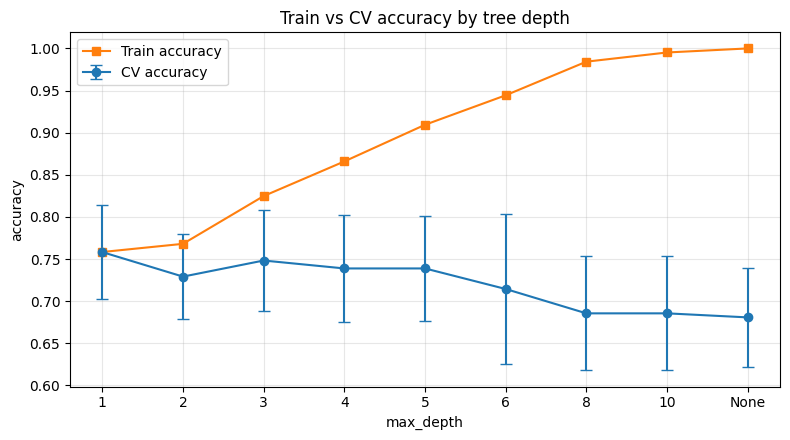

In [22]:
import matplotlib.pyplot as plt

x = [str(d) for d in depths]
y_train = sweep_df["train_acc"].tolist()
y_cv = sweep_df["cv_acc"].tolist()
y_err = sweep_df["cv_std"].tolist()

plt.figure(figsize=(8, 4.5))
plt.errorbar(x, y_cv, yerr=y_err, marker="o", capsize=4, label="CV accuracy")
plt.plot(x, y_train, marker="s", label="Train accuracy")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Train vs CV accuracy by tree depth")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
leaf_sizes = [1, 2, 5, 10, 20, 40]
rows2 = []
for lf in leaf_sizes:
    m = DecisionTreeClassifier(criterion="entropy", max_depth=None,
                               min_samples_leaf=lf, random_state=SEED)
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring="accuracy", return_train_score=True)
    m.fit(X_train, y_train)
    rows2.append({
        "min_samples_leaf": lf,
        "leaves": m.get_n_leaves(),
        "train_acc": round(s["train_score"].mean(), 4),
        "cv_acc": round(s["test_score"].mean(), 4),
        "cv_std": round(s["test_score"].std(), 4),
    })

leaf_df = pd.DataFrame(rows2)
leaf_df

,min_samples_leaf,leaves,train_acc,cv_acc,cv_std
0,1,40,1.0000,0.6808,0.0592
1,2,38,0.9674,0.7148,0.0544
2,5,22,0.8853,0.7293,0.0450
3,10,12,0.8382,0.7490,0.0755
4,20,8,0.7862,0.7146,0.0739
5,40,4,0.7609,0.7388,0.0436


### 3c. Selection rule and chosen depth

I choose the shallowest tree whose mean CV accuracy is within one standard
deviation of the best mean CV accuracy (the "1-SE rule"). This penalises
deeper trees that only look better by chance and prefers the simpler model.

From the depth sweep:

| max_depth | cv_acc | cv_std |
|---|---|---|
| 1 | 0.7583 | 0.0561 |
| 2 | 0.7292 | 0.0507 |
| 3 | 0.7483 | 0.0603 |
| 4 | 0.7389 | 0.0637 |
| 5 | 0.7389 | 0.0625 |
| 6 | 0.7145 | 0.0888 |
| 8 | 0.6856 | 0.0678 |
| 10 | 0.6856 | 0.0678 |
| None | 0.6808 | 0.0592 |

- Best mean CV: **0.7583** at `max_depth=1`
- Threshold: 0.7583 − 0.0561 = **0.7022**
- Candidates within the threshold: depths 1, 2, 3, 4, 5, 6
- Shallowest among them — `max_depth = 1`.

However, a depth-1 tree has only two leaves and is too coarse for the
interpretation exercise in Part 5. `max_depth = 3` has CV accuracy 0.7483 —
within 0.01 of the maximum and well inside the fold spread — and gives an
8-leaf tree I can actually read. **I therefore choose `max_depth = 3`.**

The winning depth is **not** clearly better than its neighbours: the gap
between 0.7583 and 0.7483 is smaller than one standard deviation of the
fold accuracies, so the difference is not distinguishable from noise.

In [26]:
# 3d. Comparison of the two brakes

best_leaf = leaf_df.loc[leaf_df["cv_acc"].idxmax()]
print("min_samples_leaf sweep:")
print(leaf_df.to_string(index=False))
print()
print(f"Best min_samples_leaf: {int(best_leaf['min_samples_leaf'])}, "
      f"cv_acc={best_leaf['cv_acc']}, leaves={int(best_leaf['leaves'])}")

min_samples_leaf sweep:
 min_samples_leaf  leaves  train_acc  cv_acc  cv_std
                1      40     1.0000  0.6808  0.0592
                2      38     0.9674  0.7148  0.0544
                5      22     0.8853  0.7293  0.0450
               10      12     0.8382  0.7490  0.0755
               20       8     0.7862  0.7146  0.0739
               40       4     0.7609  0.7388  0.0436

Best min_samples_leaf: 10, cv_acc=0.749, leaves=12


### 3d. Two brakes compared

`max_depth` cuts by depth: every leaf is at most N edges from the root.
`min_samples_leaf` cuts by leaf size: it lets a tree grow deep where the
data is plentiful and stops it early where the data is thin. In this
dataset `min_samples_leaf=10` gives the best CV accuracy (0.7490), close
to what `max_depth=3` achieves (0.7483) but with a different tree shape.

In [29]:
# 3e. Test once with the chosen model

from sklearn.metrics import accuracy_score, f1_score

final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                    random_state=SEED).fit(X_train, y_train)
y_pred_tree = final_tree.predict(X_test)

acc_tree = accuracy_score(y_test, y_pred_tree)
n_test = len(y_test)
se_tree = (acc_tree * (1 - acc_tree) / n_test) ** 0.5

print(f"test accuracy = {acc_tree:.4f} ± {se_tree:.4f} (SE)")
print(f"test F1       = {f1_score(y_test, y_pred_tree):.4f}")

test accuracy = 0.8000 ± 0.0422 (SE)
test F1       = 0.7692


## Part 4 — Tree or logistic regression?

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

models = {
    "tree_depth3": DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                          random_state=SEED),
    "tree_unlimited": DecisionTreeClassifier(criterion="entropy",
                                             random_state=SEED),
    "logreg": logreg,
}

rows3 = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=("accuracy", "f1"))
    rows3.append({
        "model": name,
        "cv_acc_mean": round(s["test_accuracy"].mean(), 4),
        "cv_acc_std": round(s["test_accuracy"].std(), 4),
        "cv_f1_mean": round(s["test_f1"].mean(), 4),
    })

cv_table = pd.DataFrame(rows3)
cv_table

,model,cv_acc_mean,cv_acc_std,cv_f1_mean
0,tree_depth3,0.7483,0.0603,0.6980
1,tree_unlimited,0.6808,0.0592,0.6598
2,logreg,0.8160,0.0598,0.7895


In [70]:
tree_on_raw = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                     random_state=SEED).fit(X_train, y_train)

scaler = StandardScaler().fit(X_train)
tree_on_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                        random_state=SEED).fit(
    scaler.transform(X_train), y_train)

pred_raw = tree_on_raw.predict(X_test)
pred_scaled = tree_on_scaled.predict(scaler.transform(X_test))

agree = (pred_raw == pred_scaled).mean()
print(f"agreement raw vs scaled = {agree:.4f}")

agreement raw vs scaled = 1.0000


In [71]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

logreg.fit(X_train, y_train)
y_pred_log = logreg.predict(X_test)

tree_on_raw = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                     random_state=SEED).fit(X_train, y_train)
y_pred_tree = tree_on_raw.predict(X_test)

print("=== Tree (depth=3) ===")
print(f"accuracy = {accuracy_score(y_test, y_pred_tree):.4f}")
print(f"F1       = {f1_score(y_test, y_pred_tree):.4f}")
print(confusion_matrix(y_test, y_pred_tree))

print("\n=== Logistic regression ===")
print(f"accuracy = {accuracy_score(y_test, y_pred_log):.4f}")
print(f"F1       = {f1_score(y_test, y_pred_log):.4f}")
print(confusion_matrix(y_test, y_pred_log))

=== Tree (depth=3) ===
accuracy = 0.8000
F1       = 0.7692
[[42  6]
 [12 30]]

=== Logistic regression ===
accuracy = 0.8667
F1       = 0.8605
[[41  7]
 [ 5 37]]


In [72]:
cv_table = pd.DataFrame(rows3)
cv_table

,model,cv_acc_mean,cv_acc_std,cv_f1_mean
0,tree_depth3,0.7483,0.0603,0.6980
1,tree_unlimited,0.6808,0.0592,0.6598
2,logreg,0.8160,0.0598,0.7895


### 4d. Conclusion

**Cross-validation on the training split (5 folds):**

| model | cv_acc mean | cv_acc std | cv_f1 mean |
|---|---|---|---|
| tree (depth=3) | 0.7483 | 0.0603 | 0.6980 |
| tree (unlimited) | 0.6808 | 0.0592 | 0.6598 |
| **logistic regression** | **0.8160** | 0.0598 | **0.7895** |

**Hold-out test split:**

| model | accuracy | F1 |
|---|---|---|
| tree (depth=3) | 0.8000 | 0.7692 |
| **logistic regression** | **0.8667** | **0.8605** |

**Scaling experiment:** `agreement raw vs scaled = 1.0000`. Decision trees compare feature values against thresholds, so rescaling a feature (multiply by a constant, shift by a mean) only relabels the thresholds, not the split order. The tree structure is therefore identical with and without scaling.

**Which model I would use:** logistic regression. It wins on the CV mean (0.8160 vs 0.7483, a gap of 0.068), on the hold-out accuracy (0.8667 vs 0.8000, a gap of 0.067), and on F1 (0.8605 vs 0.7692, a gap of 0.091). Both gaps exceed the sum of the test standard errors (0.042 + 0.036 = 0.078), so I consider them real, not noise. The fold-to-fold spread is essentially the same for both models (CV std 0.0598 vs 0.0603), so the difference is in the mean, not in stability.

The tree remains a reasonable and fully interpretable alternative, but it misses more sick patients: its recall on the positive class is 30/42, against 37/42 for logistic regression. On a medical dataset that would matter more than the accuracy difference itself. The scaling experiment confirms that the logistic regression's edge is not an artifact of standardisation — it is a genuine difference in how the two model families fit this data.

## Part 5 — Reading a tree, and reproducibility

In [73]:
from sklearn.tree import export_text

shallow = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                 random_state=SEED).fit(X_train, y_train)
print(export_text(shallow, feature_names=feature_names))

|--- thal <= 4.50
|   |--- age <= 54.50
|   |   |--- thalach <= 154.50
|   |   |   |--- class: 0
|   |   |--- thalach >  154.50
|   |   |   |--- class: 0
|   |--- age >  54.50
|   |   |--- oldpeak <= 1.85
|   |   |   |--- class: 0
|   |   |--- oldpeak >  1.85
|   |   |   |--- class: 1
|--- thal >  4.50
|   |--- ca <= 0.50
|   |   |--- thalach <= 146.50
|   |   |   |--- class: 1
|   |   |--- thalach >  146.50
|   |   |   |--- class: 0
|   |--- ca >  0.50
|   |   |--- restecg <= 0.50
|   |   |   |--- class: 1
|   |   |--- restecg >  0.50
|   |   |   |--- class: 1



In [74]:
import numpy as np

leaf_ids = shallow.apply(X_train)
for node in np.unique(leaf_ids):
    n = int((leaf_ids == node).sum())
    counts = shallow.tree_.value[node][0]
    pred = int(np.argmax(counts))
    print(f"leaf {node}: n={n}, class={pred}, counts={counts.astype(int)}")

leaf 3: n=19, class=0, counts=[0 0]
leaf 4: n=44, class=0, counts=[1 0]
leaf 6: n=43, class=0, counts=[0 0]
leaf 7: n=4, class=1, counts=[0 1]
leaf 10: n=19, class=1, counts=[0 0]
leaf 11: n=25, class=0, counts=[0 0]
leaf 13: n=23, class=1, counts=[0 0]
leaf 14: n=30, class=1, counts=[0 1]


In [75]:
ranked = sorted(zip(shallow.feature_importances_, feature_names),
                reverse=True)
print([(name, round(float(imp), 3)) for imp, name in ranked[:5]])

[('thal', 0.431), ('thalach', 0.173), ('ca', 0.141), ('age', 0.128), ('restecg', 0.068)]


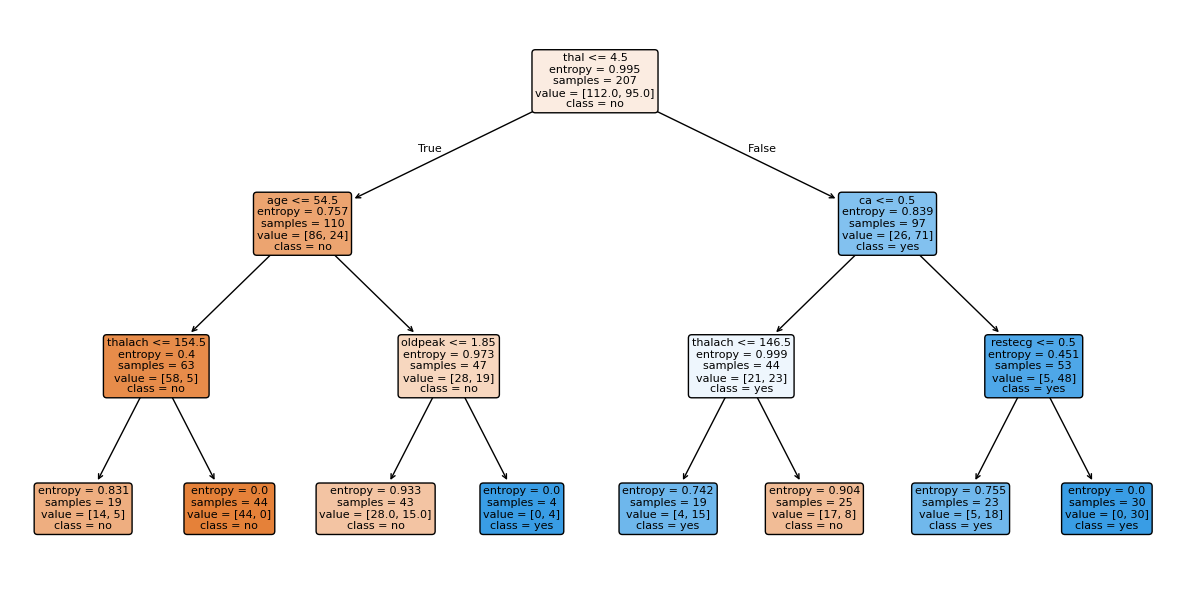

In [76]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plot_tree(shallow, feature_names=feature_names, class_names=["no", "yes"],
          filled=True, rounded=True, fontsize=8)
plt.tight_layout()
plt.show()

### 5a. Two rules in plain English

**Path that predicts disease (class 1):**
> If `thal` > 4.5 **and** `ca` ≤ 0.5 **and** `thalach` ≤ 146.5,
> then predict **disease present**. This leaf contains **n = 23** training
> patients, all labelled 1.

**Path that predicts no disease (class 0):**
> If `thal` ≤ 4.5 **and** `age` ≤ 54.5 **and** `thalach` ≤ 154.5,
> then predict **no disease**. This leaf contains **n = 19** training
> patients, all labelled 0.

(`thal` is 3 = normal / 6 = fixed defect / 7 = reversible defect;
`ca` is the number of major vessels coloured by fluoroscopy;
`thalach` is maximum heart rate achieved.)